# Final results: when should a medical RAG system answer, retrieve again, or abstain?

This notebook only reads files in `results/final/` (written by `python -m evrag.evaluation.tune`,
`python -m evrag.evaluation.retrieval_eval`, `scripts/run_final.py` and `scripts/final_metrics.py`);
it runs no model. Figures are also saved to `results/figures/` for the slides.
Thresholds were tuned on **dev** only; every table below is on **test** unless it says otherwise.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from evrag.config import FIGURES_DIR, FINAL_DIR, dataset_paths
from evrag.evaluation.metrics import load_dataset, load_runs

SETS = ["coronavirus", "cancer", "neuro"]
METHODS = ["nlp_only", "basic_rag", "graph_rag", "threshold_rag", "evidence_rag"]
# One fixed categorical colour per method in every figure (validated reference palette, slots 1-5).
COLORS = dict(zip(METHODS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
RETRIEVER_COLORS = dict(zip(["tfidf", "bm25", "minilm", "graph"], ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
SCENARIOS = ["answerable", "missing_evidence", "out_of_domain"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 2,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "legend.frameon": False, "font.size": 10,
                     "figure.constrained_layout.use": True})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)


def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


metrics = pd.read_csv(FINAL_DIR / "metrics.csv")
unseen = pd.read_csv(FINAL_DIR / "metrics_unseen.csv")
thresholds = json.loads((FINAL_DIR / "thresholds.json").read_text())
runs = {(d, m, s): {r["question_id"]: r for r in load_runs([FINAL_DIR / "runs" / d / f"{m}_{s}.jsonl"])}
        for d in SETS for m in METHODS for s in ("dev", "test")}
questions = {(d, s): load_dataset(dataset_paths(d)["dataset"], s) for d in SETS for s in ("dev", "test")}
test = metrics[metrics.split == "test"]

## 1. Datasets

Three single-disease knowledge bases, each from a different source. Each evaluation set adds two
kinds of unanswerable questions (`src/evrag/data/unanswerable.py`): **missing evidence** (the gold
passages were removed from the corpus, other passages of the same page remain) and **out of domain**
(questions from the other two sets). `seen` counts answerable questions whose gold answer overlaps
the generator's training data (`train_overlap.csv`).

In [2]:
rows = []
for d in SETS:
    corpus = sum(1 for _ in open(dataset_paths(d)["corpus"]))
    seen = pd.read_csv(dataset_paths(d)["corpus"].parent / "train_overlap.csv")
    for s in ("dev", "test"):
        q = pd.DataFrame(questions[(d, s)].values())
        counts = q.scenario.value_counts()
        rows.append({"dataset": d, "split": s, "passages": corpus, **{c: counts.get(c, 0) for c in SCENARIOS},
                     "seen in generator training": int(seen[seen.question_id.isin(q.question_id)].seen.sum())})
pd.DataFrame(rows)

,dataset,split,passages,answerable,missing_evidence,out_of_domain,seen in generator training
0,coronavirus,dev,922,107,25,50,0
1,coronavirus,test,922,106,25,50,0
2,cancer,dev,3844,125,25,50,9
3,cancer,test,3844,125,25,50,15
4,neuro,dev,1333,125,25,50,5
5,neuro,test,1333,125,25,50,9


## 2. Retrievers: traditional term weighting vs dense embeddings

Retrieval only, on the answerable test questions (`python -m evrag.evaluation.retrieval_eval`).
BM25 is our own implementation of Okapi BM25 (k1 = 1.5, b = 0.75); TF-IDF uses scikit-learn.

In [3]:
retrieval = pd.read_csv(FINAL_DIR / "retrieval.csv")
retrieval.pivot(index="retriever", columns="dataset", values=["recall_at_1", "recall_at_5", "mrr"]) \
    .reindex(["tfidf", "bm25", "minilm", "graph"])

recall_at_1                    recall_at_5                     \
dataset        cancer coronavirus  neuro      cancer coronavirus  neuro   
retriever                                                                 
tfidf           0.120       0.566  0.232       0.392       0.774  0.848   
bm25            0.264       0.604  0.376       0.616       0.792  0.904   
minilm          0.504       0.274  0.736       0.912       0.434  0.984   
graph           0.448       0.557  0.552       0.832       0.783  0.888   

             mrr                     
dataset   cancer coronavirus  neuro  
retriever                            
tfidf      0.249       0.662  0.465  
bm25       0.416       0.689  0.575  
minilm     0.680       0.348  0.843  
graph      0.624       0.662  0.690

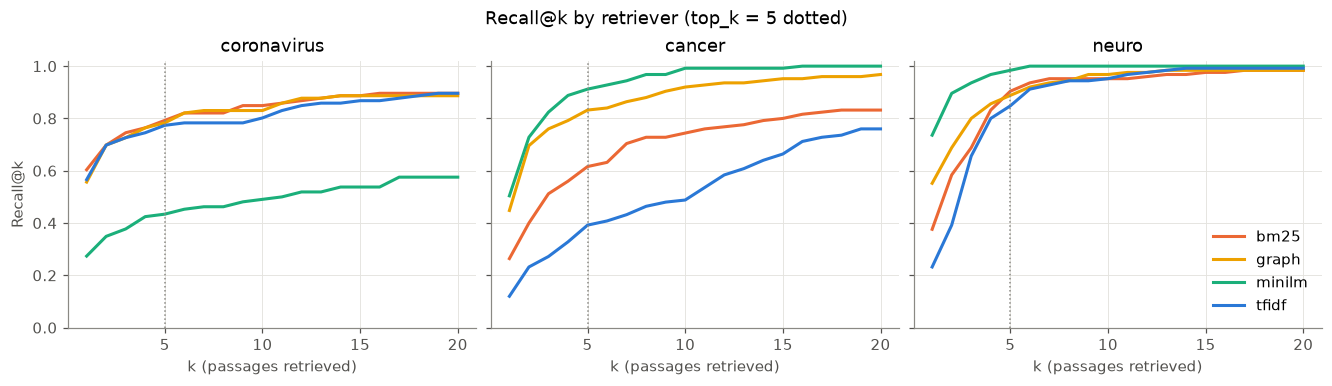

In [4]:
curve = pd.read_csv(FINAL_DIR / "recall_curve.csv")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, d in zip(axes, SETS):
    for name, g in curve[curve.dataset == d].groupby("retriever"):
        ax.plot(g.k, g.recall, color=RETRIEVER_COLORS[name], label=name)
    ax.axvline(5, color="#8a8984", lw=1, ls=":")
    ax.set(title=d, xlabel="k (passages retrieved)", ylim=(0, 1.02))
axes[0].set_ylabel("Recall@k")
axes[-1].legend(loc="lower right")
fig.suptitle("Recall@k by retriever (top_k = 5 dotted)")
save(fig, "recall_at_k")

## 3. Main table: five methods on three datasets (test)

`answer_correctness` counts an answer correct when its token F1 with a gold answer is at least 0.5
(95% bootstrap interval); `reliability` also credits abstaining on unanswerable questions.
`gold_token_recall` is the share of the gold answer's words found in the answer: COVID-QA gold
answers are short spans while the generator writes full sentences, so F1 understates it there.

In [5]:
main_cols = ["coverage", "answer_correctness", "answer_correctness_ci_low", "answer_correctness_ci_high",
             "selective_accuracy", "reliability", "abstention_recall", "over_refusal_rate",
             "unsupported_answer_rate", "token_f1", "rouge_l", "gold_token_recall", "bleu4", "meteor", "latency_mean_ms"]
main = test[test.scenario == "all"].set_index(["dataset", "method"])[main_cols]
main = main.reindex([(d, m) for d in SETS for m in METHODS])
main

coverage  answer_correctness  \
dataset     method                                        
coronavirus nlp_only          1.000               0.000   
            basic_rag         1.000               0.055   
            graph_rag         0.956               0.127   
            threshold_rag     0.530               0.028   
            evidence_rag      0.613               0.055   
cancer      nlp_only          1.000               0.005   
            basic_rag         1.000               0.205   
            graph_rag         0.960               0.185   
            threshold_rag     0.710               0.200   
            evidence_rag      0.735               0.215   
neuro       nlp_only          1.000               0.000   
            basic_rag         1.000               0.335   
            graph_rag         0.995               0.310   
            threshold_rag     0.720               0.330   
            evidence_rag      0.695               0.320   

                           answer_correctness_ci_low  \
dataset     method                                     
coronavirus nlp_only                           0.000   
            basic_rag                          0.028   
            graph_rag                          0.083   
            threshold_rag                      0.005   
            evidence_rag                       0.028   
cancer      nlp_only                           0.000   
            basic_rag                          0.150   
            graph_rag                          0.135   
            threshold_rag                      0.145   
            evidence_rag                       0.160   
neuro       nlp_only                           0.000   
            basic_rag                          0.270   
            graph_rag                          0.245   
            threshold_rag                      0.265   
            evidence_rag                       0.255   

                           answer_correctness_ci_high  selective_accuracy  \
dataset     method                                                          
coronavirus nlp_only                            0.000               0.000   
            basic_rag                           0.094               0.055   
            graph_rag                           0.182               0.133   
            threshold_rag                       0.055               0.052   
            evidence_rag                        0.094               0.090   
cancer      nlp_only                            0.015               0.005   
            basic_rag                           0.265               0.205   
            graph_rag                           0.240               0.193   
            threshold_rag                       0.260               0.282   
            evidence_rag                        0.275               0.292   
neuro       nlp_only                            0.000               0.000   
            basic_rag                           0.405               0.335   
            graph_rag                           0.380               0.312   
            threshold_rag                       0.395               0.458   
            evidence_rag                        0.390               0.460   

                           reliability  abstention_recall  over_refusal_rate  \
dataset     method                                                             
coronavirus nlp_only             0.000              0.000              0.000   
            basic_rag            0.055              0.000              0.000   
            graph_rag            0.171              0.107              0.000   
            threshold_rag        0.304              0.667              0.330   
            evidence_rag         0.304              0.600              0.236   
cancer      nlp_only             0.005              0.000              0.000   
            basic_rag            0.205              0.000              0.000   
            graph_rag            0.225  

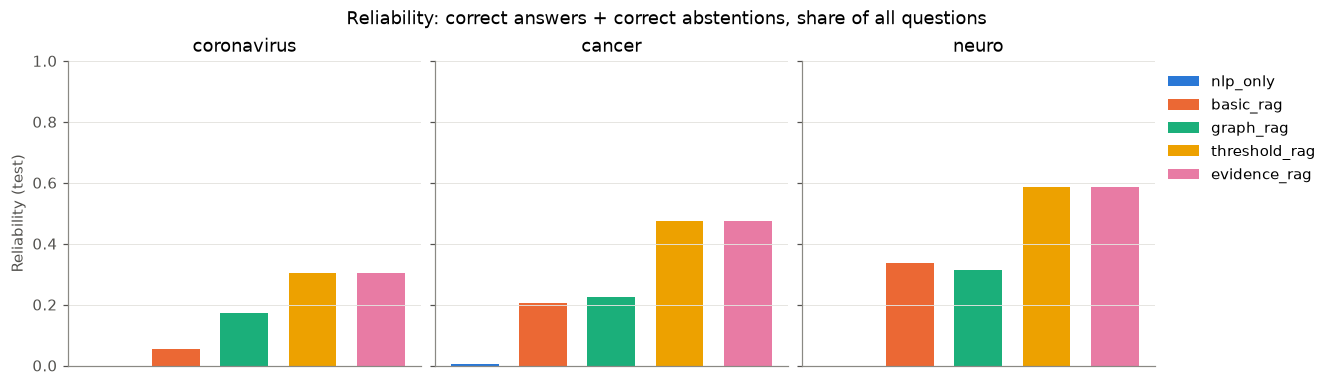

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, d in zip(axes, SETS):
    sub = main.loc[d]
    for i, m in enumerate(METHODS):
        r = sub.loc[m]
        ax.bar(i, r.reliability, color=COLORS[m], width=0.7, label=m)
    ax.set(title=d, xticks=[], ylim=(0, 1))
axes[0].set_ylabel("Reliability (test)")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle("Reliability: correct answers + correct abstentions, share of all questions")
save(fig, "reliability")

Paired bootstrap on the same test questions: evidence_rag minus each baseline (the gap is reliable when the interval excludes 0).

In [7]:
paired = pd.read_csv(FINAL_DIR / "paired.csv")
paired["significant"] = (paired.ci_low > 0) | (paired.ci_high < 0)
paired.pivot_table(index=["dataset", "baseline"], columns="metric", values=["diff", "ci_low", "ci_high"]).round(3)

ci_high                         ci_low  \
metric                    answer_correctness reliability answer_correctness   
dataset     baseline                                                          
cancer      basic_rag                  0.030       0.335             -0.010   
            graph_rag                  0.090       0.335             -0.030   
            nlp_only                   0.270       0.540              0.155   
            threshold_rag              0.035       0.025              0.000   
coronavirus basic_rag                  0.000       0.315              0.000   
            graph_rag                 -0.033       0.210             -0.116   
            nlp_only                   0.094       0.376              0.028   
            threshold_rag              0.055       0.050              0.006   
neuro       basic_rag                  0.015       0.320             -0.045   
            graph_rag                  0.070       0.355             -0.050   
            nlp_only                   0.385       0.655              0.255   
            threshold_rag              0.020       0.035             -0.040   

                                                    diff              
metric                    reliability answer_correctness reliability  
dataset     baseline                                                  
cancer      basic_rag           0.205              0.010       0.270  
            graph_rag           0.165              0.030       0.250  
            nlp_only            0.405              0.210       0.470  
            threshold_rag      -0.025              0.015       0.000  
coronavirus basic_rag           0.188              0.000       0.249  
            graph_rag           0.061             -0.072       0.133  
            nlp_only            0.238              0.055       0.304  
            threshold_rag      -0.050              0.028       0.000  
neuro       basic_rag           0.185             -0.015       0.250  
            graph_rag           0.190              0.010       0.270  
            nlp_only            0.515              0.320       0.585  
            threshold_rag      -0.035             -0.010       0.000

## 4. Abstention by scenario (test)

In [8]:
by = test[test.scenario.isin(SCENARIOS)].copy()
by["right decision"] = np.where(by.scenario == "answerable", 1 - by.over_refusal_rate, by.abstention_recall)
by.pivot_table(index=["dataset", "method"], columns="scenario", values="right decision") \
    .reindex([(d, m) for d in SETS for m in METHODS])

scenario                   answerable  missing_evidence  out_of_domain
dataset     method                                                    
coronavirus nlp_only            1.000              0.00           0.00
            basic_rag           1.000              0.00           0.00
            graph_rag           1.000              0.00           0.16
            threshold_rag       0.670              0.28           0.86
            evidence_rag        0.764              0.16           0.82
cancer      nlp_only            1.000              0.00           0.00
            basic_rag           1.000              0.00           0.00
            graph_rag           1.000              0.00           0.16
            threshold_rag       0.976              0.20           1.00
            evidence_rag        0.992              0.08           1.00
neuro       nlp_only            1.000              0.00           0.00
            basic_rag           1.000              0.00           0.00
            graph_rag           1.000              0.00           0.02
            threshold_rag       0.960              0.04           1.00
            evidence_rag        0.936              0.16           0.98

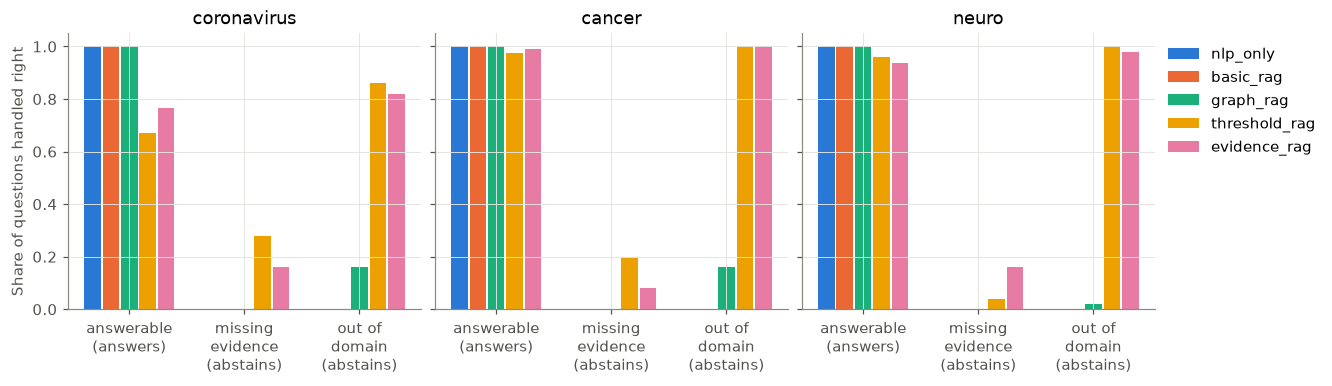

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
width = 0.16
for ax, d in zip(axes, SETS):
    sub = by[by.dataset == d].set_index(["method", "scenario"])["right decision"]
    for i, m in enumerate(METHODS):
        ax.bar(np.arange(3) + (i - 2) * width, [sub.get((m, s), np.nan) for s in SCENARIOS], width * 0.9,
               color=COLORS[m], label=m)
    ax.set(title=d, xticks=range(3), xticklabels=["answerable\n(answers)", "missing\nevidence\n(abstains)",
                                                  "out of\ndomain\n(abstains)"], ylim=(0, 1.05))
axes[0].set_ylabel("Share of questions handled right")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1, 1))
save(fig, "abstention_by_scenario")

## 5. Risk-coverage and hyper-parameter curves

Left: basic_rag answers only when its top-1 score reaches τ; sweeping τ trades coverage for
selective accuracy (test). The dots are the dev-tuned operating points of threshold_rag and
evidence_rag. Right: Youden's J (abstention recall − over-refusal) of the threshold on **dev**,
the objective used to pick τ.

/var/folders/jx/flbh03ts46vcnv013z_2h90c0000gn/T/ipykernel_83118/3303192691.py:22: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


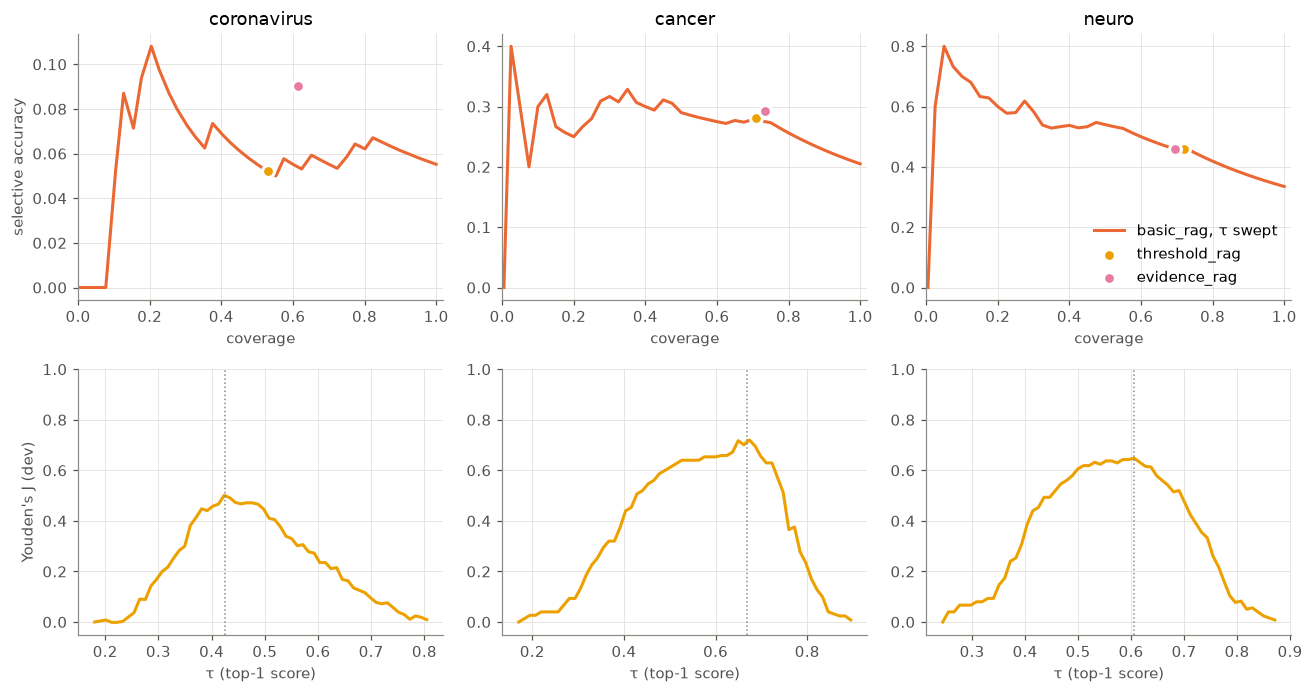

In [10]:
rc = pd.read_csv(FINAL_DIR / "risk_coverage.csv")
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for col, d in enumerate(SETS):
    ax = axes[0, col]
    g = rc[(rc.dataset == d) & (rc.split == "test")].sort_values("coverage")
    ax.plot(g.coverage, g.selective_accuracy, color=COLORS["basic_rag"], label="basic_rag, τ swept")
    for m in ("threshold_rag", "evidence_rag"):
        r = main.loc[(d, m)]
        ax.scatter(r.coverage, r.selective_accuracy, s=60, color=COLORS[m], edgecolor="white", linewidth=2, zorder=3, label=m)
    ax.set(title=d, xlabel="coverage", xlim=(0, 1.02))
    ax = axes[1, col]
    sig = pd.read_csv(FINAL_DIR / "signals" / f"{d}_dev.csv")
    taus = np.linspace(sig.score.min(), sig.score.max(), 60)
    ans = sig.answerable.astype(bool).values
    j = [(~(sig.score.values >= t)[~ans]).mean() - (~(sig.score.values >= t)[ans]).mean() for t in taus]
    ax.plot(taus, j, color=COLORS["threshold_rag"])
    ax.axvline(thresholds[d]["threshold_rag"]["tau"], color="#8a8984", lw=1, ls=":")
    ax.set(xlabel="τ (top-1 score)", ylim=(-0.05, 1))
axes[0, 0].set_ylabel("selective accuracy")
axes[1, 0].set_ylabel("Youden's J (dev)")
axes[0, -1].legend(loc="lower right")
fig.tight_layout()
save(fig, "risk_coverage")

## 6. evidence_rag decisions

How often it answers at once, retrieves again, or abstains, per scenario (test), and whether the
second retrieval found a gold passage that the first one missed (answerable questions it retried).

In [11]:
dec = []
for d in SETS:
    for qid, r in runs[(d, "evidence_rag", "test")].items():
        q = questions[(d, "test")][qid]
        gold = set(q["gold_doc_ids"])
        first, final = set(r["meta"]["initial_doc_ids"]), {x["doc_id"] for x in r["retrieved_docs"]}
        dec.append({"dataset": d, "scenario": q["scenario"], "action": r["meta"]["action"], "retried": r["meta"]["retried"],
                    "gold_before": bool(gold & first) if gold else None, "gold_after": bool(gold & final) if gold else None})
dec = pd.DataFrame(dec)
actions = pd.crosstab([dec.dataset, dec.scenario], dec.action, normalize="index").reindex(columns=["answer", "retry_answer", "abstain"])
actions

action                        answer  retry_answer  abstain
dataset     scenario                                       
cancer      answerable         0.888         0.104    0.008
            missing_evidence   0.560         0.360    0.080
            out_of_domain      0.000         0.000    1.000
coronavirus answerable         0.698         0.066    0.236
            missing_evidence   0.800         0.040    0.160
            out_of_domain      0.080         0.100    0.820
neuro       answerable         0.832         0.104    0.064
            missing_evidence   0.560         0.280    0.160
            out_of_domain      0.000         0.020    0.980

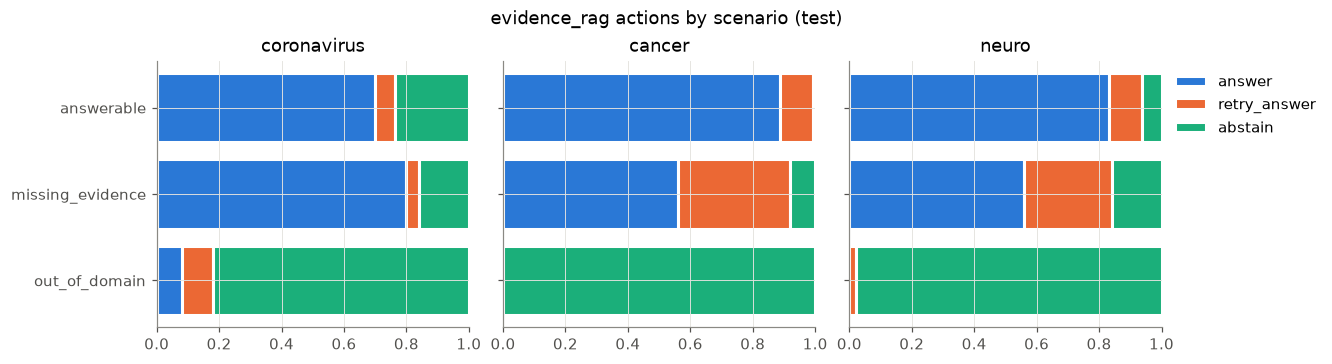

In [12]:
ACTION_COLORS = {"answer": "#2a78d6", "retry_answer": "#eb6834", "abstain": "#1baf7a"}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, d in zip(axes, SETS):
    left = np.zeros(3)
    sub = actions.loc[d].reindex(SCENARIOS)
    for a in ["answer", "retry_answer", "abstain"]:
        ax.barh(range(3), sub[a], left=left, color=ACTION_COLORS[a], edgecolor="white", linewidth=2, label=a)
        left += sub[a].values
    ax.set(title=d, yticks=range(3), yticklabels=SCENARIOS, xlim=(0, 1))
    ax.invert_yaxis()
axes[-1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle("evidence_rag actions by scenario (test)")
save(fig, "evidence_actions")

In [13]:
retried = dec[dec.retried & (dec.scenario == "answerable")]
retried.groupby("dataset")[["gold_before", "gold_after"]].mean().assign(n=retried.groupby("dataset").size())

,gold_before,gold_after,n
dataset,,,
cancer,0.929,0.857,14
coronavirus,0.219,0.094,32
neuro,1.0,0.905,21


## 7. Examples (test)

In [14]:
def show(d, qid, methods=("basic_rag", "evidence_rag")):
    q = questions[(d, "test")][qid]
    lines = [f"**[{d} · {q['scenario']}] {q['question']}**", f"- gold: {(q['gold_answers'] or ['(none: unanswerable)'])[0][:300]}"]
    for m in methods:
        r = runs[(d, m, "test")][qid]
        extra = ""
        if m == "evidence_rag":
            s = r["meta"]["signals"]
            extra = f" — {r['meta']['action']}; s1 {s['initial']['score']:.2f}, s2 {s['initial']['coverage']:.2f}"
            if "retry" in s:
                extra += f" → retry s1 {s['retry']['score']:.2f}, s2 {s['retry']['coverage']:.2f} (+ {', '.join(r['meta']['expansion_terms'])})"
        lines.append(f"- {m}: {'*abstained*' if r['abstained'] else r['answer'][:300]}{extra}")
    display(Markdown("\n".join(lines)))


def pick(d, scenario, action, n=2):
    ids = [qid for qid, r in runs[(d, "evidence_rag", "test")].items()
           if questions[(d, "test")][qid]["scenario"] == scenario and r["meta"]["action"] == action]
    return ids[:n]


for d, scenario, action in [("cancer", "answerable", "answer"), ("neuro", "answerable", "retry_answer"),
                            ("cancer", "missing_evidence", "abstain"), ("neuro", "missing_evidence", "answer"),
                            ("coronavirus", "out_of_domain", "abstain"), ("coronavirus", "answerable", "abstain")]:
    display(Markdown(f"### {d}: {scenario}, evidence_rag {action}"))
    for qid in pick(d, scenario, action):
        show(d, qid)

### cancer: answerable, evidence_rag answer

**[cancer · answerable] What is the outlook for Adult Acute Lymphoblastic Leukemia ?**
- gold: Certain factors affect prognosis (chance of recovery) and treatment options. The prognosis (chance of recovery) and treatment options depend on the following: - The age of the patient. - Whether the cancer has spread to the brain or spinal cord. - Whether there are certain changes in the genes, incl
- basic_rag: Adult Acute Lymphoblastic Leukemia: Certain factors affect prognosis (chance of recovery) and treatment options.
- evidence_rag: Adult Acute Lymphoblastic Leukemia: Certain factors affect prognosis (chance of recovery) and treatment options. — answer; s1 0.75, s2 0.63

**[cancer · answerable] What is the outlook for Adult Acute Myeloid Leukemia ?**
- gold: Certain factors affect prognosis (chance of recovery) and treatment options. The prognosis (chance of recovery) and treatment options depend on: - The age of the patient. - The subtype of AML. - Whether the patient received chemotherapy in the past to treat a different cancer. - Whether there is a h
- basic_rag: Adult Acute Myeloid Leukemia: Certain factors affect prognosis (chance of recovery) and treatment options. The prognosis depends on the age of the patient, the subtype of AML, whether the patient received chemotherapy in the past to treat a different cancer, whether there is a history of a blood dis
- evidence_rag: Adult Acute Myeloid Leukemia: Certain factors affect prognosis (chance of recovery) and treatment options. The prognosis depends on the age of the patient, the subtype of AML, whether the patient received chemotherapy in the past to treat a different cancer, whether there is a history of a blood dis — answer; s1 0.78, s2 0.62

### neuro: answerable, evidence_rag retry_answer

**[neuro · answerable] What is (are) Agenesis of the Corpus Callosum ?**
- gold: Agenesis of the corpus callosum (ACC) is one of several disorders of the corpus callosum, the structure that connects the two hemispheres (left and right) of the brain. In ACC the corpus callosum is partially or completely absent. It is caused by a disruption of brain cell migration during fetal dev
- basic_rag: Agenesis of the Corpus Callosum: There is no standard course of treatment for ACC. Treatment usually involves management of symptoms and seizures if they occur. Associated difficulties are much more manageable with early recognition and therapy, especially therapies focusing on left/right coordinati
- evidence_rag: Agenesis of the Corpus Callosum: Agenesis can also be associated with malformations in other parts of the body, such as midline facial defects. The effects of the disorder range from subtle or mild to severe, depending on associated brain abnormalities. — retry_answer; s1 0.62, s2 1.00 → retry s1 0.76, s2 1.00 (+ acc, abnormalities, malformations, midline, associated)

**[neuro · answerable] What is (are) Anencephaly ?**
- gold: Anencephaly is a defect in the closure of the neural tube during fetal development. The neural tube is a narrow channel that folds and closes between the 3rd and 4th weeks of pregnancy to form the brain and spinal cord of the embryo. Anencephaly occurs when the "cephalic" or head end of the neural t
- basic_rag: Anencephaly is a defect in the closure of the neural tube during fetal development. The neural tube is a narrow channel that folds and closes between the 3rd and 4th weeks of pregnancy to form the brain and spinal cord of the embryo.
- evidence_rag: Anencephaly is a defect in the closure of the neural tube during fetal development. The neural tube is a narrow channel that folds and closes between the 3rd and 4th weeks of pregnancy to form the brain and spinal cord of the embryo. — retry_answer; s1 0.59, s2 1.00 → retry s1 0.78, s2 1.00 (+ neural, tube, born, brain, cerebrum)

... (8 outputs left out)

**[coronavirus · out_of_domain] What are the symptoms of Primary Myelofibrosis ?**
- gold: (none: unanswerable)
- basic_rag: Patients in severe condition may have shortness of breath, moist rales in lungs, weakened breath sounds, dullness in percussion, and increased or decreased tactile speech tremor, etc. The imaging findings vary with the patient's age, immunity status, disease stage at the time of scanning, underlying
- evidence_rag: *abstained* — abstain; s1 0.31, s2 0.20 → retry s1 0.39, s2 0.20 (+ reactions, oxygen, etc, patients, adverse)

### coronavirus: answerable, evidence_rag abstain

**[coronavirus · answerable] Which species are more prevalent but less severe?**
- gold: HCoV-HKU1, HCoV-OC43, HCoV-NL63, and HCoV-229E
- basic_rag: A super-spreading ewe infects hundreds with Q fever at a farmers' market in Germany: mentioned Swiss outbreak, 46% of serologically positive patients developed clinical disease
- evidence_rag: *abstained* — abstain; s1 0.38, s2 0.00 → retry s1 0.58, s2 0.00 (+ seroprevalence, flocks, flock, sheep, children)

**[coronavirus · answerable] Who performed the sampling procedures?**
- gold: veterinarians
- basic_rag: Optimization Method for Forecasting Confirmed Cases of COVID-19 in China: movement. where λ = 1.5. Γ(λ) denotes the gamma function. This distribution is available for large steps s > 0.
- evidence_rag: *abstained* — abstain; s1 0.25, s2 0.00 → retry s1 0.46, s2 0.00 (+ pollination, ssa, salps, followers, used)

## 8. Robustness: without answers the generator may have seen

Answerable questions flagged in `train_overlap.csv` are removed (cancer 24, neuro 14 over both
splits; coronavirus none).

In [15]:
cols = ["answer_correctness", "reliability", "token_f1"]
both = pd.concat({"all questions": test[test.scenario == "all"].set_index(["dataset", "method"])[cols],
                  "without seen": unseen[(unseen.split == "test") & (unseen.scenario == "all")].set_index(["dataset", "method"])[cols]}, axis=1)
both.reindex([(d, m) for d in ("cancer", "neuro") for m in METHODS])

all questions                       \
                      answer_correctness reliability token_f1   
dataset method                                                  
cancer  nlp_only                   0.005       0.005    0.227   
        basic_rag                  0.205       0.205    0.440   
        graph_rag                  0.185       0.225    0.395   
        threshold_rag              0.200       0.475    0.440   
        evidence_rag               0.215       0.475    0.453   
neuro   nlp_only                   0.000       0.000    0.152   
        basic_rag                  0.335       0.335    0.556   
        graph_rag                  0.310       0.315    0.541   
        threshold_rag              0.330       0.585    0.565   
        evidence_rag               0.320       0.585    0.562   

                            without seen                       
                      answer_correctness reliability token_f1  
dataset method                                                 
cancer  nlp_only                   0.005       0.005    0.221  
        basic_rag                  0.184       0.184    0.434  
        graph_rag                  0.168       0.211    0.387  
        threshold_rag              0.184       0.481    0.435  
        evidence_rag               0.200       0.481    0.450  
neuro   nlp_only                   0.000       0.000    0.153  
        basic_rag                  0.340       0.340    0.568  
        graph_rag                  0.309       0.314    0.547  
        threshold_rag              0.335       0.602    0.578  
        evidence_rag               0.319       0.597    0.571

## Findings

1. **Retrieval is what makes the generator useful.** Closed-book `nlp_only` almost never gets an
   answer right (answer correctness ≤ 0.005 on all three sets); every retrieval route is far ahead
   (paired intervals exclude 0).
2. **Abstaining raises reliability by about 0.25 on every set.** Reliability (correct answers plus
   correct abstentions) goes from 0.06 / 0.21 / 0.34 for `basic_rag` to 0.30 / 0.48 / 0.59 for
   `evidence_rag` (coronavirus / cancer / neuro), while answer correctness stays within ±0.02 of
   `basic_rag` on cancer and neuro. On cancer, over-refusal is 0.8%.
3. **`evidence_rag` is not better than the simpler `threshold_rag`.** Their reliability is the same on
   all three test sets (paired difference 0.000, intervals around 0). The coverage signal and the
   retry add nothing measurable over a single score threshold.
4. **Out-of-domain questions are caught; missing evidence is not.** Both abstaining methods reject
   82–100% of out-of-domain questions but still answer 72–96% of missing-evidence questions: when
   the gold passage is deleted, a passage on the same disease remains and scores almost as high.
   This is the main open problem.
5. **Retrieving again rarely helps.** On answerable questions it retried, the expanded query kept or
   lost the gold passage instead of finding it (questions with a gold passage in the top 5: 7 → 3 on
   coronavirus, 13 → 12 on cancer, 21 → 19 on neuro). Retries are also what let some
   missing-evidence questions through.
6. **On coronavirus, use gold token recall.** COVID-QA gold answers are short spans, so token F1 ≥ 0.5
   is near zero for all methods. By gold token recall, `graph_rag` is best (0.55 against 0.38 for
   `basic_rag`), in line with its stronger lexical retrieval on this set (section 2).
7. **Results hold without answers the generator may have seen** (section 8): removing them changes
   cancer and neuro answer correctness and reliability by at most about 0.02.

## Limitations

- **Generator training overlap.** MEDIQA-AnS, part of the generator's training data, takes its
  sections from NIH pages including cancer.gov and NINDS, which MedQuAD also uses (section 8).
- **COVID-QA retrieval is hard for dense embeddings** (MiniLM Recall@5 0.43 against BM25 0.79), so
  every dense route starts from weak evidence there; the graph route is lexical and does better.
- **Automatic correctness** is token F1 ≥ 0.5 with a gold answer. It understates long correct
  answers to short-span questions (COVID-QA) and rewards copying the gold passage (MedQuAD, whose
  gold answer is a whole page section). Answers also repeat the passage heading the generator
  copies. No manual adjudication was done for these sets.
- **Unanswerable questions are constructed**: 43% of each evaluation set, more than in real use, and
  missing evidence is simulated by deleting passages.
- **The generator never abstains by itself** and was not retrained; all abstention comes from the
  policies around it. Thresholds come from 182–200 dev questions per set.